# Predicting NYC Taxi Trip Duration — Deliverables 1 and 2
**Dataset:** NYC taxi trips, March 2019 (6,433-trip sample of NYC TLC trip records, distributed with seaborn)


## 1. Setup and load data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from scipy.stats import loguniform, randint
import time
sns.set_theme(style='whitegrid'); RANDOM_STATE = 42

URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv'
df = pd.read_csv(URL, parse_dates=['pickup','dropoff'])
print('Shape:', df.shape)
df.head()

Shape: (6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

## 2. Target and data quality checks
The target is trip **duration in minutes** (dropoff time minus pickup time).

In [3]:
df['duration'] = (df['dropoff'] - df['pickup']).dt.total_seconds() / 60
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
print('Trips under 1 minute :', (df['duration'] < 1).sum())
print('Trips with 0 distance:', (df['distance'] == 0).sum())
print('Trips with 0 passengers:', (df['passengers'] == 0).sum())
print('Date range:', df['pickup'].min().date(), 'to', df['pickup'].max().date())
df[['duration','distance','passengers']].describe().round(2)

Missing values per column:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Duplicate rows: 0
Trips under 1 minute : 72
Trips with 0 distance: 51
Trips with 0 passengers: 96
Date range: 2019-02-28 to 2019-03-31


,duration,distance,passengers
count,6433.00,6433.00,6433.00
mean,14.35,3.02,1.54
std,11.64,3.83,1.20
min,0.00,0.00,0.00
25%,6.50,0.98,1.00
50%,10.90,1.64,1.00
75%,18.52,3.21,2.00
max,107.67,36.70,6.00


## 3. Exploratory data analysis

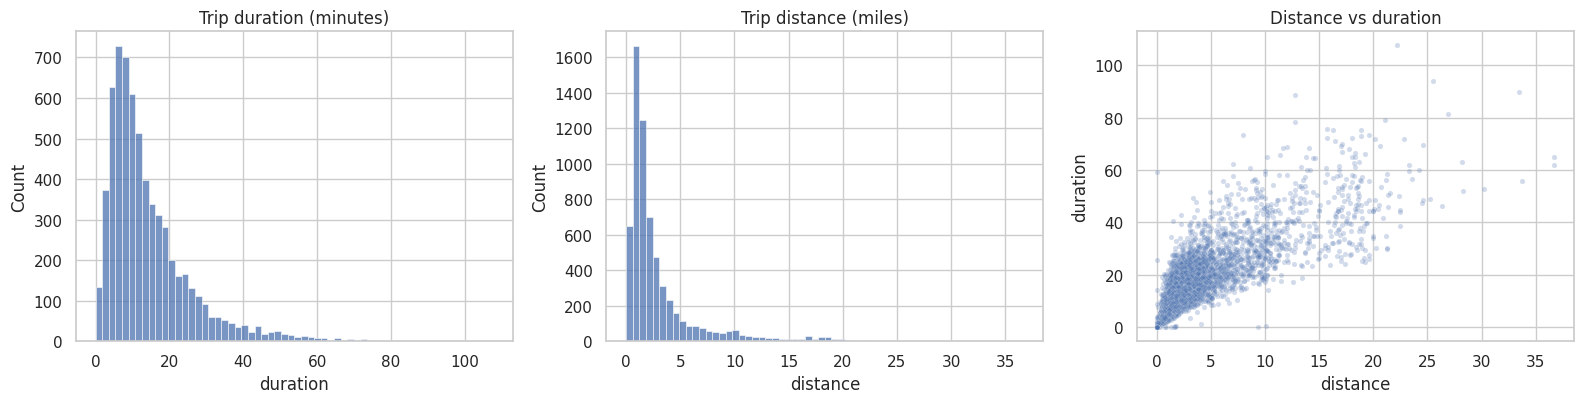

Correlation, distance vs duration: 0.821


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df['duration'], bins=60, ax=ax[0]); ax[0].set_title('Trip duration (minutes)')
sns.histplot(df['distance'], bins=60, ax=ax[1]); ax[1].set_title('Trip distance (miles)')
sns.scatterplot(x='distance', y='duration', data=df, alpha=0.25, s=14, ax=ax[2]); ax[2].set_title('Distance vs duration')
plt.tight_layout(); plt.show()
print('Correlation, distance vs duration: %.3f' % df[['distance','duration']].corr().iloc[0,1])

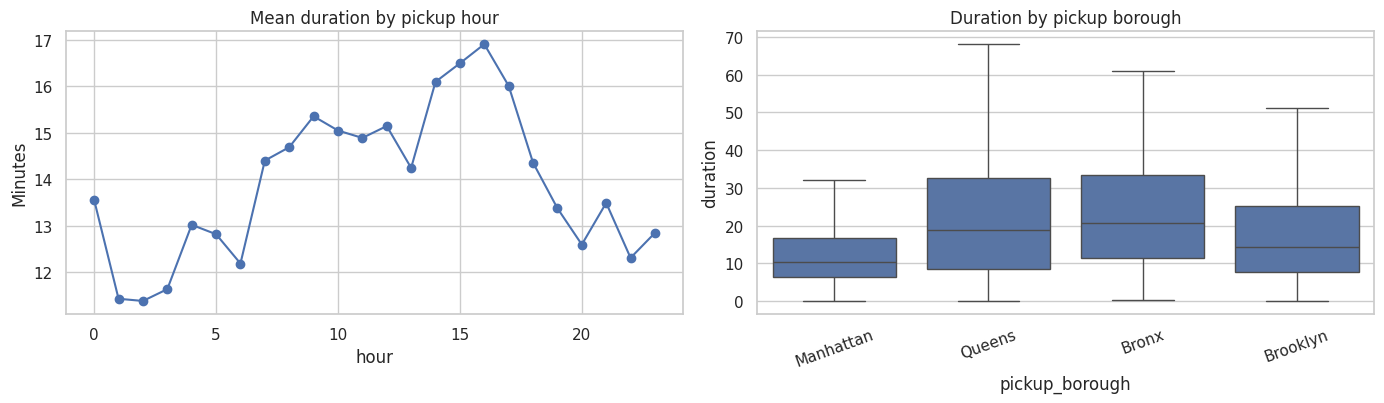

In [5]:
df['hour'] = df['pickup'].dt.hour
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
df.groupby('hour')['duration'].mean().plot(marker='o', ax=ax[0]); ax[0].set_title('Mean duration by pickup hour'); ax[0].set_ylabel('Minutes')
sns.boxplot(x='pickup_borough', y='duration', data=df, ax=ax[1], showfliers=False); ax[1].set_title('Duration by pickup borough'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## 4. Cleaning and feature engineering

In [6]:
clean = df.copy()
before = len(clean)
# Remove trips that are not plausible completed rides: under 1 minute or zero distance
clean = clean[(clean['duration'] >= 1) & (clean['distance'] > 0)].copy()
print('Rows removed:', before - len(clean), '| rows kept:', len(clean))

# Missing location / payment fields: keep the rows, mark as Unknown
for c in ['pickup_borough','dropoff_borough','pickup_zone','dropoff_zone','payment']:
    clean[c] = clean[c].fillna('Unknown')
# 0 passengers is a data-entry artifact: set to 1
clean['passengers'] = clean['passengers'].clip(lower=1)

clean['hour'] = clean['pickup'].dt.hour
clean['dayofweek'] = clean['pickup'].dt.dayofweek
clean['is_weekend'] = (clean['dayofweek'] >= 5).astype(int)
clean['is_rush'] = (((clean['hour'].between(7, 9)) | (clean['hour'].between(16, 19))) & (clean['is_weekend'] == 0)).astype(int)
clean['same_borough'] = (clean['pickup_borough'] == clean['dropoff_borough']).astype(int)
print(clean[['duration','distance','hour','is_rush','same_borough']].describe().round(2))

Rows removed: 83 | rows kept: 6350
       duration  distance     hour  is_rush  same_borough
count   6350.00   6350.00  6350.00  6350.00       6350.00
mean      14.51      3.06    13.88     0.28          0.87
std       11.60      3.84     6.07     0.45          0.34
min        1.00      0.09     0.00     0.00          0.00
25%        6.65      1.00    10.00     0.00          1.00
50%       11.00      1.67    15.00     0.00          1.00
75%       18.60      3.25    19.00     1.00          1.00
max      107.67     36.70    23.00     1.00          1.00


In [7]:
# Leakage check: fare, tip, tolls and total are only known after the trip (fare depends on the meter's time and distance),
# so they are NOT used as inputs.
BASE_NUM = ['distance','passengers','hour','dayofweek','is_weekend','is_rush','same_borough']
BASE_CAT = ['color','pickup_borough','dropoff_borough']
ZONE_CAT = ['pickup_zone','dropoff_zone']
X = clean[BASE_NUM + BASE_CAT + ZONE_CAT]; y = clean['duration']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Mean duration  train: %.2f   test: %.2f min' % (y_train.mean(), y_test.mean()))

prep_base = ColumnTransformer([('num', StandardScaler(), BASE_NUM),
                               ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), BASE_CAT)])

Train: (5080, 12)  Test: (1270, 12)
Mean duration  train: 14.49   test: 14.63 min


## 5. Initial model

In [8]:
def evaluate(name, model, Xt=None):
    Xt = X_test if Xt is None else Xt
    p = model.predict(Xt)
    return {'Model': name, 'MAE (min)': mean_absolute_error(y_test, p),
            'RMSE (min)': np.sqrt(mean_squared_error(y_test, p)), 'R²': r2_score(y_test, p),
            'Median abs. error (min)': median_absolute_error(y_test, p)}

dummy = Pipeline([('prep', prep_base), ('reg', DummyRegressor(strategy='mean'))]).fit(X_train, y_train)
lin   = Pipeline([('prep', prep_base), ('reg', LinearRegression())]).fit(X_train, y_train)
results1 = pd.DataFrame([evaluate('Mean-duration baseline', dummy), evaluate('Linear regression (initial)', lin)]).set_index('Model').round(3)
results1

,MAE (min),RMSE (min),R²,Median abs. error (min)
Model,,,,
Mean-duration baseline,8.707,12.391,-0.000,6.945
Linear regression (initial),4.560,6.566,0.719,3.403


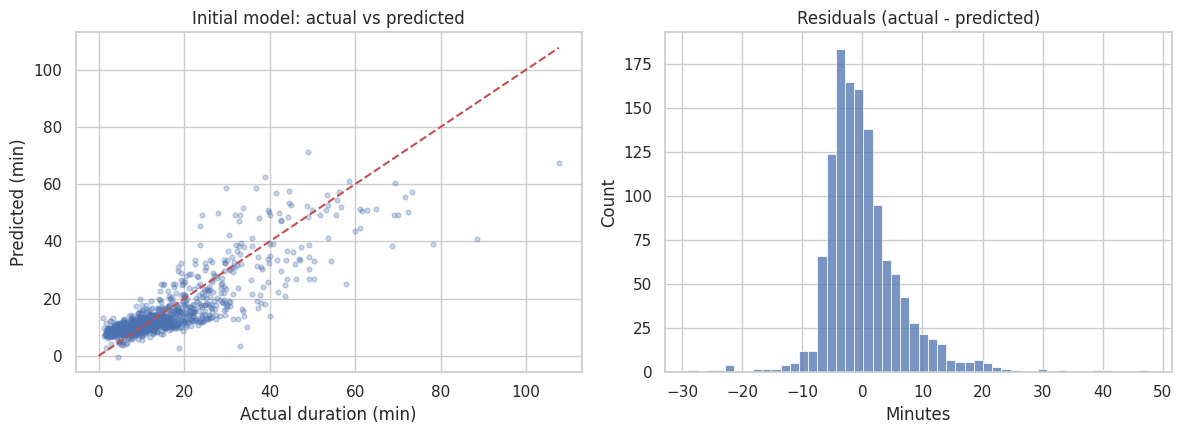

cat__dropoff_borough_Staten Island   -11.31
cat__dropoff_borough_Unknown          -6.27
cat__pickup_borough_Queens            -3.34
num__is_weekend                       -0.67
cat__dropoff_borough_Bronx             3.81
cat__dropoff_borough_Manhattan         4.56
cat__dropoff_borough_Brooklyn          5.84
num__distance                          9.46
dtype: float64


In [9]:
p_lin = lin.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, p_lin, alpha=0.3, s=12); lim = [0, max(y_test.max(), p_lin.max())]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Actual duration (min)'); ax[0].set_ylabel('Predicted (min)'); ax[0].set_title('Initial model: actual vs predicted')
sns.histplot(y_test - p_lin, bins=50, ax=ax[1]); ax[1].set_title('Residuals (actual - predicted)'); ax[1].set_xlabel('Minutes')
plt.tight_layout(); plt.show()
coef = pd.Series(lin.named_steps['reg'].coef_, index=lin.named_steps['prep'].get_feature_names_out()).sort_values()
print(pd.concat([coef.head(4), coef.tail(4)]).round(2))

## 6. Observations and next steps
- Distance alone explains most of the variation, so the linear model is a strong baseline, but it assumes a straight-line relationship.
- Residuals fan out for long trips; the target is right-skewed, so a log transform and non-linear models are the first things to try.
- Next: add pickup/dropoff zones, compare tree-based models with cross-validation, tune hyperparameters, and audit errors by borough and time of day.

## 7. Compare candidate models with cross-validation
All model selection uses 5-fold cross-validation on the **training set only**. The test set stays untouched until section 9. 'Extended' features add pickup and dropoff zones.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
prep_ext = ColumnTransformer([('num', StandardScaler(), BASE_NUM),
                              ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=15, sparse_output=False), BASE_CAT + ZONE_CAT)])
def logt(reg): return TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)

candidates = {
    'Linear regression (initial)':        lin,
    'Ridge, extended features':           Pipeline([('prep', prep_ext), ('reg', Ridge(alpha=10))]),
    'Random forest, extended':            Pipeline([('prep', prep_ext), ('reg', RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE))]),
    'Gradient boosting, extended':        Pipeline([('prep', prep_ext), ('reg', HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
    'Gradient boosting, log target':      Pipeline([('prep', prep_ext), ('reg', logt(HistGradientBoostingRegressor(random_state=RANDOM_STATE)))]),
}
rows = []
for name, model in candidates.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=['neg_mean_absolute_error','neg_root_mean_squared_error','r2'], n_jobs=-1)
    rows.append({'Model': name, 'CV MAE': -s['test_neg_mean_absolute_error'].mean(), 'CV RMSE': -s['test_neg_root_mean_squared_error'].mean(), 'CV R²': s['test_r2'].mean()})
cv_table = pd.DataFrame(rows).set_index('Model').round(3)
cv_table

,CV MAE,CV RMSE,CV R²
Model,,,
Linear regression (initial),4.530,6.368,0.685
"Ridge, extended features",4.304,6.122,0.709
"Random forest, extended",3.377,5.154,0.794
"Gradient boosting, extended",3.248,4.972,0.808
"Gradient boosting, log target",3.155,4.952,0.810


### 7.1 Experiment log: what we tried and what happened
Model selection is trial and error, so we keep a log. Every experiment below is scored with the **same 5 fold cross-validation on the training set only** (the test set is still untouched). Each trial is recorded in `log`, and section 7.8 turns it into one table and a decision.

**Working rule:** a change is kept only if it lowers cross-validated RMSE by more than the fold-to-fold noise measured in 7.2. Otherwise we keep the simpler setup.

In [11]:
log = []
def trial(group, name, model, Xtr=None):
    Xtr = X_train if Xtr is None else Xtr
    s = cross_validate(model, Xtr, y_train, cv=cv, scoring=['neg_mean_absolute_error','neg_root_mean_squared_error','r2'], n_jobs=-1)
    row = {'Group': group, 'Trial': name, 'CV MAE': -s['test_neg_mean_absolute_error'].mean(),
           'CV RMSE': -s['test_neg_root_mean_squared_error'].mean(), 'CV R²': s['test_r2'].mean()}
    log.append(row); return pd.Series(row)
hgb = lambda **k: HistGradientBoostingRegressor(random_state=RANDOM_STATE, **k)
def make_prep(num=BASE_NUM, cat=BASE_CAT + ZONE_CAT):
    return ColumnTransformer([('num', StandardScaler(), num),
                              ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=15, sparse_output=False), cat)])
ref = trial('Reference', 'Gradient boosting, log target', Pipeline([('prep', prep_ext), ('reg', logt(hgb()))]))
ref

,0
Group,Reference
Trial,"Gradient boosting, log target"
CV MAE,3.154932
CV RMSE,4.952429
CV R²,0.810063


### 7.2 How much is noise? Repeated cross-validation
Before reading small differences as real, we measure how much the score moves just from how the folds are cut: 5-fold CV repeated 3 times with different shuffles.

In [12]:
from sklearn.model_selection import RepeatedKFold
rcv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=7)
def repeated(name, model):
    s = -cross_validate(model, X_train, y_train, cv=rcv, scoring='neg_root_mean_squared_error', n_jobs=-1)['test_score']
    return {'Setup': name, 'RMSE mean': s.mean(), 'RMSE std (across 15 folds)': s.std()}
noise = pd.DataFrame([
    repeated('GB, log target',  Pipeline([('prep', prep_ext), ('reg', logt(hgb()))])),
    repeated('GB, sqrt target', Pipeline([('prep', prep_ext), ('reg', TransformedTargetRegressor(regressor=hgb(), func=np.sqrt, inverse_func=np.square))])),
    repeated('GB, raw target',  Pipeline([('prep', prep_ext), ('reg', hgb())])),
]).set_index('Setup').round(3)
NOISE = noise['RMSE std (across 15 folds)'].max()
print('Differences smaller than about %.2f min RMSE are within fold-to-fold noise.' % NOISE)
noise

Differences smaller than about 0.19 min RMSE are within fold-to-fold noise.


,RMSE mean,RMSE std (across 15 folds)
Setup,,
"GB, log target",4.899,0.187
"GB, sqrt target",4.873,0.183
"GB, raw target",4.935,0.174


### 7.3 Experiment A: what should the model predict? (target transform and loss)
Trip durations are right-skewed. We tried predicting the raw minutes, the square root, the log, and a loss that targets the median error instead of the squared error.

In [13]:
sq = lambda reg: TransformedTargetRegressor(regressor=reg, func=np.sqrt, inverse_func=np.square)
pd.DataFrame([
    trial('A. Target / loss', 'Raw target',                  Pipeline([('prep', prep_ext), ('reg', hgb())])),
    trial('A. Target / loss', 'Square-root target',          Pipeline([('prep', prep_ext), ('reg', sq(hgb()))])),
    trial('A. Target / loss', 'Log target (reference)',      Pipeline([('prep', prep_ext), ('reg', logt(hgb()))])),
    trial('A. Target / loss', 'Log target, absolute-error loss', Pipeline([('prep', prep_ext), ('reg', logt(hgb(loss='absolute_error')))])),
]).set_index('Trial').drop(columns='Group').round(3)

,CV MAE,CV RMSE,CV R²
Trial,,,
Raw target,3.248,4.972,0.808
Square-root target,3.168,4.914,0.813
Log target (reference),3.155,4.952,0.810
"Log target, absolute-error loss",3.159,5.020,0.805


### 7.4 Experiment B: more model families (including ones that failed)
We tried regularized linear models, a nearest-neighbour model, and other tree ensembles. Not every idea works; the failures are part of the record.

In [14]:
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
fam = pd.DataFrame([
    trial('B. Model family', 'Lasso, log target',       Pipeline([('prep', prep_ext), ('reg', logt(Lasso(alpha=0.001)))])),
    trial('B. Model family', 'ElasticNet, log target',  Pipeline([('prep', prep_ext), ('reg', logt(ElasticNet(alpha=0.001, l1_ratio=0.5)))])),
    trial('B. Model family', 'K-nearest neighbours (k=15), log target', Pipeline([('prep', prep_ext), ('reg', logt(KNeighborsRegressor(15, weights='distance')))])),
    trial('B. Model family', 'Extra trees, log target', Pipeline([('prep', prep_ext), ('reg', logt(ExtraTreesRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)))])),
    trial('B. Model family', 'Random forest, log target', Pipeline([('prep', prep_ext), ('reg', logt(RandomForestRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)))])),
]).set_index('Trial').drop(columns='Group').round(3)
fam

,CV MAE,CV RMSE,CV R²
Trial,,,
"Lasso, log target",6.376,22.491,-5.384
"ElasticNet, log target",6.330,21.882,-4.740
"K-nearest neighbours (k=15), log target",5.019,7.163,0.601
"Extra trees, log target",3.366,5.312,0.782
"Random forest, log target",3.322,5.185,0.792


**Reading the failures.** The linear models on a log target are much worse (RMSE above 20 minutes). A linear model on the log scale can predict a very large log-duration for an unusual trip, and converting back with `expm1` turns that into an absurd number of minutes. Nearest neighbours does poorly because most of the signal is in distance, and a distance-based method treats the one-hot zone columns as equally important. Tree ensembles handle both well, which is why gradient boosting stays the lead model.

### 7.5 Experiment C: feature ablation
We drop one feature (or group) at a time and re-score. A large rise in error means the feature carries real signal; no change means it is redundant.

In [15]:
groups = {'passengers': ['passengers'], 'hour': ['hour'], 'day of week + weekend': ['dayofweek','is_weekend'],
          'rush-hour flag': ['is_rush'], 'same-borough flag': ['same_borough'], 'dropoff borough': ['dropoff_borough'],
          'pickup + dropoff zone': ['pickup_zone','dropoff_zone'], 'taxi color': ['color']}
abl = []
for name, drop in groups.items():
    num = [c for c in BASE_NUM if c not in drop]; cat = [c for c in BASE_CAT + ZONE_CAT if c not in drop]
    r = trial('C. Ablation', 'Drop ' + name, Pipeline([('prep', make_prep(num, cat)), ('reg', logt(hgb()))]), X_train.drop(columns=drop))
    abl.append({'Dropped': name, 'CV RMSE': r['CV RMSE'], 'Change vs reference': r['CV RMSE'] - ref['CV RMSE']})
abl = pd.DataFrame(abl).set_index('Dropped').sort_values('Change vs reference', ascending=False).round(3)
abl

,CV RMSE,Change vs reference
Dropped,,
hour,5.650,0.698
pickup + dropoff zone,5.144,0.191
day of week + weekend,5.103,0.151
dropoff borough,4.975,0.022
taxi color,4.974,0.022
passengers,4.958,0.005
same-borough flag,4.950,-0.002
rush-hour flag,4.936,-0.016


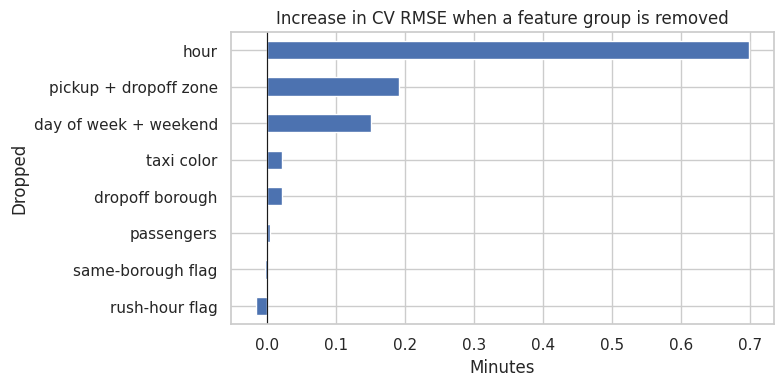

In [16]:
abl['Change vs reference'].sort_values().plot(kind='barh', figsize=(7, 3.8), title='Increase in CV RMSE when a feature group is removed')
plt.axvline(0, color='k', lw=0.8); plt.xlabel('Minutes'); plt.show()

### 7.6 Experiment D: new features
Based on the earlier residual plots we tried features that might help the model: a smooth (cyclic) version of the hour, log and squared distance, a distance x rush-hour interaction, and a late-night flag.

In [17]:
def add_features(d):
    d = d.copy()
    d['hour_sin'] = np.sin(2*np.pi*d['hour']/24); d['hour_cos'] = np.cos(2*np.pi*d['hour']/24)
    d['log_dist'] = np.log1p(d['distance']); d['dist_sq'] = d['distance']**2
    d['dist_x_rush'] = d['distance']*d['is_rush']; d['night'] = ((d['hour'] >= 22) | (d['hour'] <= 5)).astype(int)
    return d
X_train_fe = add_features(X_train)
new_sets = {'Cyclic hour (sin, cos)': ['hour_sin','hour_cos'], 'Log + squared distance': ['log_dist','dist_sq'],
            'Distance x rush hour': ['dist_x_rush'], 'Late-night flag': ['night'],
            'All of the above': ['hour_sin','hour_cos','log_dist','dist_sq','dist_x_rush','night']}
fe = pd.DataFrame([trial('D. New features', 'Add ' + k, Pipeline([('prep', make_prep(BASE_NUM + v)), ('reg', logt(hgb()))]), X_train_fe)
                   for k, v in new_sets.items()]).set_index('Trial').drop(columns='Group').round(3)
fe

,CV MAE,CV RMSE,CV R²
Trial,,,
"Add Cyclic hour (sin, cos)",3.151,4.941,0.811
Add Log + squared distance,3.155,4.952,0.810
Add Distance x rush hour,3.159,4.962,0.809
Add Late-night flag,3.150,4.955,0.810
Add All of the above,3.163,4.945,0.811


### 7.7 Experiment E: outliers, ensembles, and how much data helps

In [18]:
# (1) Trim the longest 1% of trips from the TRAINING part of each fold only; validation folds stay untouched
errs = []
for tr, va in cv.split(X_train):
    yt = y_train.iloc[tr]; keep = (yt <= yt.quantile(0.99)).values
    m = Pipeline([('prep', prep_ext), ('reg', logt(hgb()))]).fit(X_train.iloc[tr][keep], yt[keep])
    errs.append(np.sqrt(mean_squared_error(y_train.iloc[va], m.predict(X_train.iloc[va]))))
log.append({'Group': 'E. Outliers / ensembles', 'Trial': 'Trim longest 1% of training trips', 'CV MAE': np.nan, 'CV RMSE': np.mean(errs), 'CV R²': np.nan})
print('Trim longest 1%% of training trips: CV RMSE %.3f (reference %.3f)' % (np.mean(errs), ref['CV RMSE']))

# (2) Ensembles of the models already built
from sklearn.ensemble import StackingRegressor, VotingRegressor
gb_m = Pipeline([('prep', prep_ext), ('reg', logt(hgb()))])
rf_m = Pipeline([('prep', prep_ext), ('reg', logt(RandomForestRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)))])
rd_m = Pipeline([('prep', prep_ext), ('reg', Ridge(alpha=10))])
ens = pd.DataFrame([
    trial('E. Outliers / ensembles', 'Voting: GB + RF', VotingRegressor([('gb', gb_m), ('rf', rf_m)])),
    trial('E. Outliers / ensembles', 'Stacking: GB + RF + Ridge', StackingRegressor([('gb', gb_m), ('rf', rf_m), ('rd', rd_m)], final_estimator=Ridge(alpha=1), cv=5)),
]).set_index('Trial').drop(columns='Group').round(3)
ens

Trim longest 1% of training trips: CV RMSE 5.082 (reference 4.952)


,CV MAE,CV RMSE,CV R²
Trial,,,
Voting: GB + RF,3.179,4.988,0.807
Stacking: GB + RF + Ridge,3.191,4.903,0.814


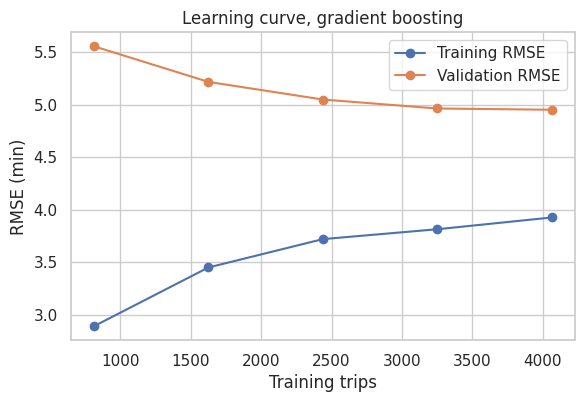

Validation RMSE gain from the last 20% of data: 0.01 min


In [19]:
from sklearn.model_selection import learning_curve
sizes, tr_s, va_s = learning_curve(gb_m, X_train, y_train, cv=cv, train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
                                   scoring='neg_root_mean_squared_error', n_jobs=-1)
plt.figure(figsize=(6.5, 4))
plt.plot(sizes, -tr_s.mean(1), 'o-', label='Training RMSE'); plt.plot(sizes, -va_s.mean(1), 'o-', label='Validation RMSE')
plt.xlabel('Training trips'); plt.ylabel('RMSE (min)'); plt.title('Learning curve, gradient boosting'); plt.legend(); plt.show()
print('Validation RMSE gain from the last 20%% of data: %.2f min' % (-va_s.mean(1)[-2] + va_s.mean(1)[-1]))

### 7.8 Decision: what the experiments tell us
All trials in one table, ranked by cross-validated RMSE, with the noise level from 7.2.

In [20]:
full = pd.DataFrame(log).set_index('Trial')
full['vs reference'] = full['CV RMSE'] - ref['CV RMSE']
full['Beats noise?'] = np.where(full['vs reference'] < -NOISE, 'Yes', 'No')
summary = full.sort_values('CV RMSE')[['Group','CV MAE','CV RMSE','CV R²','vs reference','Beats noise?']].round(3)
print('Trials run:', len(full), '| noise level (std of fold RMSE): %.3f min' % NOISE)
print('Trials that beat the reference by more than the noise:', int((full['Beats noise?'] == 'Yes').sum()))
summary

Trials run: 26 | noise level (std of fold RMSE): 0.187 min
Trials that beat the reference by more than the noise: 0


,Group,CV MAE,CV RMSE,CV R²,vs reference,Beats noise?
Trial,,,,,,
Stacking: GB + RF + Ridge,E. Outliers / ensembles,3.191,4.903,0.814,-0.050,No
Square-root target,A. Target / loss,3.168,4.914,0.813,-0.039,No
Drop rush-hour flag,C. Ablation,3.157,4.936,0.811,-0.016,No
"Add Cyclic hour (sin, cos)",D. New features,3.151,4.941,0.811,-0.011,No
Add All of the above,D. New features,3.163,4.945,0.811,-0.008,No
Drop same-borough flag,C. Ablation,3.156,4.950,0.810,-0.002,No
Log target (reference),A. Target / loss,3.155,4.952,0.810,0.000,No
"Gradient boosting, log target",Reference,3.155,4.952,0.810,0.000,No
Add Log + squared distance,D. New features,3.155,4.952,0.810,0.000,No


**Decision.**
- No change beat the reference (gradient boosting, log target, zone features) by more than the fold-to-fold noise. Square-root target, cyclic hour, and stacking were within noise of it, so we keep the simpler reference setup.
- The ablation shows hour, day of week and the pickup/dropoff zones carry real signal, while passengers, taxi colour, and the rush-hour and same-borough flags add almost nothing on their own.
- Linear models on a log target, nearest neighbours, and trimming outliers made things worse.
- The learning curve flattens, so more trips of the same kind would help only a little; new information (weather, traffic) is the better next step.

We therefore move on to tuning the reference model (section 8), then test once on the held-out set.

## 8. Hyperparameter tuning (randomized search)
Gradient boosting with a log-transformed target had the lowest cross-validated error, so we tune it.

In [21]:
param_dist = {
    'reg__regressor__learning_rate':     loguniform(0.01, 0.3),
    'reg__regressor__max_leaf_nodes':    randint(8, 64),
    'reg__regressor__max_depth':         [None, 3, 5, 8],
    'reg__regressor__min_samples_leaf':  randint(5, 60),
    'reg__regressor__l2_regularization': loguniform(1e-3, 10),
    'reg__regressor__max_iter':          randint(100, 500),
}
base = candidates['Gradient boosting, log target']
search = RandomizedSearchCV(base, param_dist, n_iter=25, scoring='neg_root_mean_squared_error', cv=cv,
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True)
t0 = time.time(); search.fit(X_train, y_train)
print('Search time: %.0f s' % (time.time() - t0))
print('Best CV RMSE: %.3f min' % -search.best_score_)
for k, v in search.best_params_.items(): print('  ', k.replace('reg__regressor__',''), '=', round(v, 4) if isinstance(v, float) else v)
final_model = search.best_estimator_

Search time: 335 s
Best CV RMSE: 4.909 min
   l2_regularization = 1.7123
   learning_rate = 0.0282
   max_depth = None
   max_iter = 485
   max_leaf_nodes = 27
   min_samples_leaf = 32


### 8.1 More tuning trials: how sensitive is the model to each setting?
The randomized search in section 8 changes many settings at once. To see which ones matter, we vary one setting at a time around the best configuration and re-score with the same 5-fold cross-validation on the training set (validation curves).

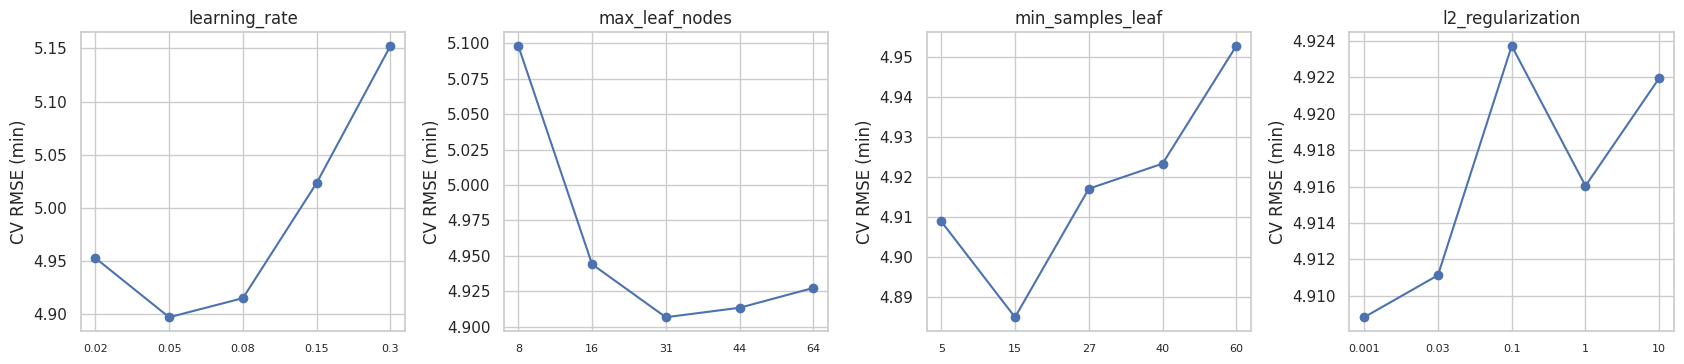

,Best CV RMSE,Worst CV RMSE,Range
Setting,,,
learning_rate,4.897,5.152,0.255
max_leaf_nodes,4.907,5.098,0.192
min_samples_leaf,4.885,4.953,0.068
l2_regularization,4.909,4.924,0.015


In [22]:
from sklearn.model_selection import validation_curve, GridSearchCV
from sklearn.experimental import enable_halving_search_cv  # noqa
from sklearn.model_selection import HalvingRandomSearchCV
best = {k.replace('reg__regressor__', ''): v for k, v in search.best_params_.items()}
sweeps = {'learning_rate': [0.02, 0.05, 0.08, 0.15, 0.3], 'max_leaf_nodes': [8, 16, 31, 44, 64],
          'min_samples_leaf': [5, 15, 27, 40, 60], 'l2_regularization': [0.001, 0.03, 0.1, 1, 10]}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8)); sens = []
for a, (p, vals) in zip(ax, sweeps.items()):
    tr, va = validation_curve(final_model, X_train, y_train, param_name='reg__regressor__' + p, param_range=vals,
                              cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    a.plot(range(len(vals)), -va.mean(1), 'o-'); a.set_xticks(range(len(vals))); a.set_xticklabels(vals, fontsize=8)
    a.set_title(p); a.set_ylabel('CV RMSE (min)')
    sens.append({'Setting': p, 'Best CV RMSE': (-va.mean(1)).min(), 'Worst CV RMSE': (-va.mean(1)).max(), 'Range': (-va.mean(1)).max() - (-va.mean(1)).min()})
plt.tight_layout(); plt.show()
pd.DataFrame(sens).set_index('Setting').round(3)

### 8.2 More tuning trials: comparing search strategies
We compare the randomized search from section 8 with two other strategies, using the same training data and folds: (1) a small **grid** around the best configuration, and (2) **successive halving**, which tries many settings on little data and keeps only the best for more data.

In [23]:
def tuned_row(name, s, secs):
    return {'Strategy': name, 'Settings tried': len(s.cv_results_['params']), 'CV RMSE': -s.best_score_, 'Time (s)': secs}
rows = [{'Strategy': 'Random search (section 8)', 'Settings tried': 25, 'CV RMSE': -search.best_score_, 'Time (s)': np.nan}]
grid = {'reg__regressor__learning_rate': [best['learning_rate']*0.5, best['learning_rate'], best['learning_rate']*2],
        'reg__regressor__max_leaf_nodes': [max(8, best['max_leaf_nodes']-16), best['max_leaf_nodes'], best['max_leaf_nodes']+16],
        'reg__regressor__min_samples_leaf': [max(5, best['min_samples_leaf']-15), best['min_samples_leaf'], best['min_samples_leaf']+15]}
for name, s in [('Grid around best', GridSearchCV(final_model, grid, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1)),
                ('Successive halving', HalvingRandomSearchCV(final_model, param_dist, n_candidates=60, factor=3, resource='n_samples',
                                                              scoring='neg_root_mean_squared_error', cv=cv, random_state=RANDOM_STATE, n_jobs=-1))]:
    t0 = time.time(); s.fit(X_train, y_train); rows.append(tuned_row(name, s, time.time() - t0))
    if name == 'Grid around best': grid_search = s
    else: halving_search = s
strat = pd.DataFrame(rows).set_index('Strategy').round(3)
strat

,Settings tried,CV RMSE,Time (s)
Strategy,,,
Random search (section 8),25,4.909,NaN
Grid around best,27,4.898,595.969
Successive halving,90,5.947,40.931


### 8.3 More tuning trials: tuning other models too
A fair comparison tunes each candidate, not only the one that looked best untuned. We tune the ridge penalty and a random forest with the same cross-validation.

In [24]:
ridge_s = GridSearchCV(Pipeline([('prep', prep_ext), ('reg', Ridge())]), {'reg__alpha': [0.1, 1, 3, 10, 30, 100]},
                       scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1).fit(X_train, y_train)
rf_s = RandomizedSearchCV(Pipeline([('prep', prep_ext), ('reg', logt(RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)))]),
                          {'reg__regressor__min_samples_leaf': [1, 2, 3, 5, 8, 12], 'reg__regressor__max_features': [0.3, 0.5, 0.8, 1.0],
                           'reg__regressor__max_depth': [None, 8, 12, 20]},
                          n_iter=15, scoring='neg_root_mean_squared_error', cv=cv, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
others = pd.DataFrame([
    {'Model': 'Ridge (best alpha = %s)' % ridge_s.best_params_['reg__alpha'], 'CV RMSE': -ridge_s.best_score_},
    {'Model': 'Random forest, tuned', 'CV RMSE': -rf_s.best_score_},
    {'Model': 'Gradient boosting, tuned (section 8)', 'CV RMSE': -search.best_score_},
]).set_index('Model').round(3)
others

,CV RMSE
Model,
Ridge (best alpha = 1),6.113
"Random forest, tuned",5.138
"Gradient boosting, tuned (section 8)",4.909


### 8.4 Decision on tuning
We switch from the section 8 model only if another setting beats its cross-validated RMSE by more than the fold-to-fold noise from section 7.2.

In [25]:
cands = {'Random search (section 8)': -search.best_score_, 'Grid around best': -grid_search.best_score_,
         'Successive halving': -halving_search.best_score_, 'Tuned random forest': -rf_s.best_score_, 'Tuned ridge': -ridge_s.best_score_}
for k, v in cands.items(): print('%-30s CV RMSE %.3f   (%.3f vs section 8)' % (k, v, v - cands['Random search (section 8)']))
switch = min(cands.values()) < cands['Random search (section 8)'] - NOISE
print('\nNoise level: %.3f min. Any option beats section 8 by more than the noise? %s' % (NOISE, 'YES' if switch else 'No - keep the section 8 model'))

Random search (section 8)      CV RMSE 4.909   (0.000 vs section 8)
Grid around best               CV RMSE 4.898   (-0.012 vs section 8)
Successive halving             CV RMSE 5.947   (1.038 vs section 8)
Tuned random forest            CV RMSE 5.138   (0.228 vs section 8)
Tuned ridge                    CV RMSE 6.113   (1.204 vs section 8)

Noise level: 0.187 min. Any option beats section 8 by more than the noise? No - keep the section 8 model


**Result.**
- No single setting moves the cross-validated error by more than the noise (8.1). The learning rate is the most sensitive (about 0.15 min across the range tried), and the regularization setting matters least.
- A small grid around the best configuration gives almost the same score as the random search (8.2). Successive halving did clearly worse (RMSE 5.95), most likely because it picks settings using small subsets of this small dataset that do not carry over to the full data.
- A tuned random forest and a tuned ridge model stay behind gradient boosting (8.3).

We therefore keep the section 8 model as final and evaluate it once on the test set.

## 9. Final evaluation on the held-out test set

In [26]:
final = pd.DataFrame([
    evaluate('1. Mean-duration baseline', dummy),
    evaluate('2. Linear regression (initial model)', lin),
    evaluate('3. Gradient boosting, untuned', candidates['Gradient boosting, log target'].fit(X_train, y_train)),
    evaluate('4. Tuned gradient boosting (final)', final_model),
]).set_index('Model').round(3)
final

,MAE (min),RMSE (min),R²,Median abs. error (min)
Model,,,,
1. Mean-duration baseline,8.707,12.391,-0.000,6.945
2. Linear regression (initial model),4.560,6.566,0.719,3.403
"3. Gradient boosting, untuned",3.032,4.916,0.843,1.860
4. Tuned gradient boosting (final),3.021,4.825,0.848,1.859


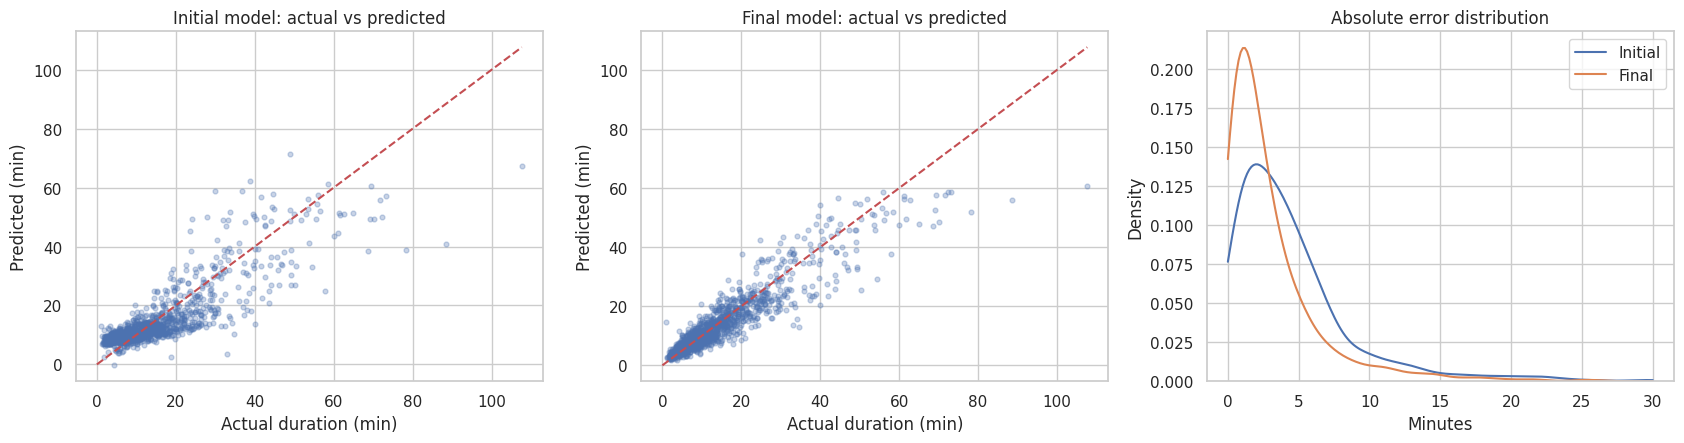

Share of test trips predicted within 3 minutes: initial 44.0%, final 67.4%
Share within 5 minutes:                         initial 68.8%, final 83.1%


In [27]:
p_final = final_model.predict(X_test)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, p, t in [(ax[0], p_lin, 'Initial model'), (ax[1], p_final, 'Final model')]:
    a.scatter(y_test, p, alpha=0.3, s=12); lim = [0, max(y_test.max(), p.max())]
    a.plot(lim, lim, 'r--'); a.set_xlabel('Actual duration (min)'); a.set_ylabel('Predicted (min)'); a.set_title(t + ': actual vs predicted')
sns.kdeplot(np.abs(y_test - p_lin), label='Initial', ax=ax[2], clip=(0, 30)); sns.kdeplot(np.abs(y_test - p_final), label='Final', ax=ax[2], clip=(0, 30))
ax[2].set_title('Absolute error distribution'); ax[2].set_xlabel('Minutes'); ax[2].legend()
plt.tight_layout(); plt.show()
print('Share of test trips predicted within 3 minutes: initial %.1f%%, final %.1f%%' % (100*(np.abs(y_test-p_lin)<=3).mean(), 100*(np.abs(y_test-p_final)<=3).mean()))
print('Share within 5 minutes:                         initial %.1f%%, final %.1f%%' % (100*(np.abs(y_test-p_lin)<=5).mean(), 100*(np.abs(y_test-p_final)<=5).mean()))

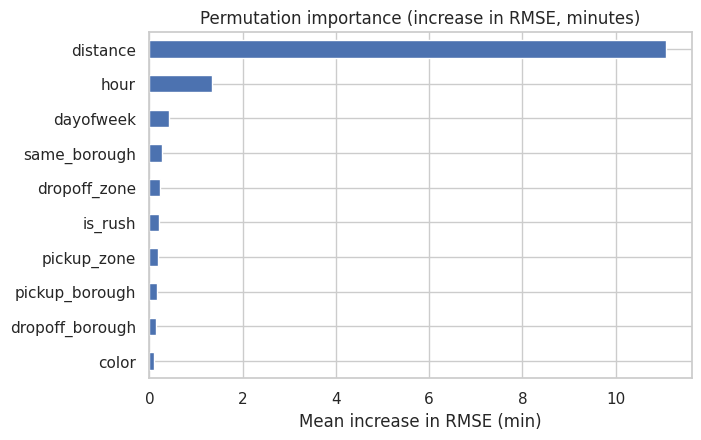

,0
distance,11.079
hour,1.335
dayofweek,0.430
same_borough,0.281
dropoff_zone,0.234
is_rush,0.199
pickup_zone,0.185
pickup_borough,0.162


In [28]:
pi = permutation_importance(final_model, X_test, y_test, scoring='neg_root_mean_squared_error', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind='barh', figsize=(7, 4.5), title='Permutation importance (increase in RMSE, minutes)')
plt.xlabel('Mean increase in RMSE (min)'); plt.show()
imp.head(8).round(3)

## 10. Error audit by group
We check whether errors differ by pickup borough, taxi type, time of day, and trip length. Bias = mean(actual - predicted); negative bias means the model over-predicts.

In [29]:
audit = X_test.copy(); audit['y'] = y_test.values; audit['p_init'] = p_lin; audit['p_final'] = p_final
audit['err_init'] = np.abs(audit['y'] - audit['p_init']); audit['err_final'] = np.abs(audit['y'] - audit['p_final'])
audit['bias_final'] = audit['y'] - audit['p_final']
audit['time_band'] = pd.cut(audit['hour'], [-1, 5, 9, 15, 19, 23], labels=['Night (0-5)','Morning (6-9)','Midday (10-15)','Evening (16-19)','Late (20-23)'])
audit['dist_band'] = pd.cut(audit['distance'], [0, 1, 3, 6, 100], labels=['<1 mi','1-3 mi','3-6 mi','6+ mi'])
def group_table(col):
    g = audit.groupby(col, observed=True)
    return pd.DataFrame({'n': g.size(), 'Mean actual (min)': g['y'].mean(), 'MAE initial': g['err_init'].mean(),
                         'MAE final': g['err_final'].mean(), 'Bias final': g['bias_final'].mean()}).round(2)
tables = {c: group_table(c) for c in ['pickup_borough','color','time_band','dist_band']}
for c, t in tables.items(): print(t, '\n')

                   n  Mean actual (min)  MAE initial  MAE final  Bias final
pickup_borough                                                             
Bronx             16              32.24         9.89       9.57        4.75
Brooklyn          66              18.40         5.61       3.41        0.44
Manhattan       1051              12.75         4.17       2.67        0.62
Queens           135              25.37         6.33       4.77        0.26
Unknown            2              11.63        10.47       4.11        4.01 

           n  Mean actual (min)  MAE initial  MAE final  Bias final
color                                                              
green    186              15.82         5.10       3.61        1.15
yellow  1084              14.42         4.47       2.92        0.54 

                   n  Mean actual (min)  MAE initial  MAE final  Bias final
time_band                                                                  
Night (0-5)       95              12.01 

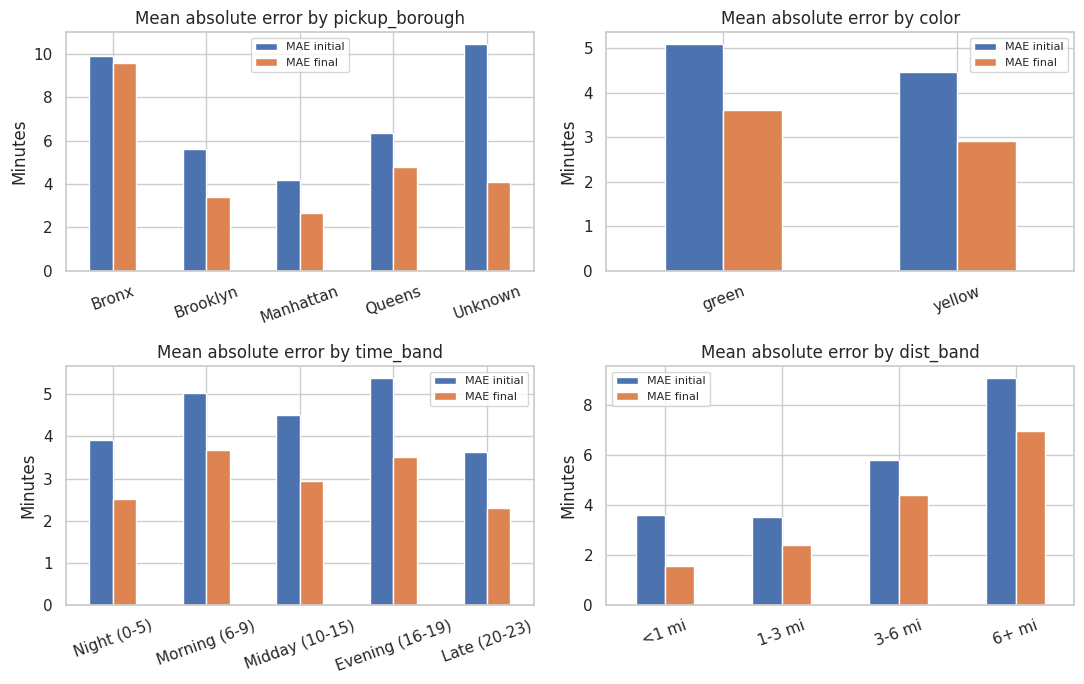

In [30]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharey=False)
for a, (c, t) in zip(ax.ravel(), tables.items()):
    t[['MAE initial','MAE final']].plot(kind='bar', ax=a, rot=20); a.set_title('Mean absolute error by ' + c); a.set_xlabel(''); a.set_ylabel('Minutes'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. How wrong can a prediction be? An 80% range
An estimate is more useful with a range. We use out-of-fold training residuals to build an 80% range and check its coverage on the test set.

In [31]:
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, n_jobs=-1)
rel = (y_train.values - oof) / oof                       # relative error, so the range widens for longer trips
lo_q, hi_q = np.quantile(rel, [0.10, 0.90])
lower = p_final * (1 + lo_q); upper = p_final * (1 + hi_q)
inside = (y_test.values >= lower) & (y_test.values <= upper)
print('Relative-error quantiles (10%%, 90%%): %.2f, %.2f' % (lo_q, hi_q))
print('Test coverage of the 80%% range: %.1f%%' % (100 * inside.mean()))
cov = pd.Series(inside, index=audit.index).groupby(audit['dist_band'], observed=True).mean().mul(100).round(1)
print('Coverage by trip length (%):'); print(cov)
ex = pd.DataFrame({'Predicted': p_final[:5].round(1), 'Low': lower[:5].round(1), 'High': upper[:5].round(1), 'Actual': y_test.values[:5].round(1)})
ex

Relative-error quantiles (10%, 90%): -0.32, 0.44
Test coverage of the 80% range: 80.8%
Coverage by trip length (%):
dist_band
<1 mi     70.2
1-3 mi    83.9
3-6 mi    85.4
6+ mi     87.9
dtype: float64


,Predicted,Low,High,Actual
0,5.6,3.8,8.0,6.2
1,56.0,38.3,80.5,62.7
2,15.0,10.3,21.6,19.1
3,13.0,8.9,18.7,19.7
4,18.1,12.4,26.1,21.5


## 12. Summary
- The tuned gradient boosting model with a log-transformed target and zone features beats the initial linear regression on every test-set error measure.
- Errors are not uniform: see section 10 for group differences before using the model operationally.
- We ran a logged set of experiments (target transforms, other model families, feature ablation, new features, outlier trimming, ensembles, a learning curve). None beat the reference by more than the noise, so the final model stays simple (section 7.8).
- Predictions should be shown as a range; section 11 shows how well an 80% range holds up.